# Exercise 5

5.1-

In [2]:
import numpy as np
# zero order coordinate search
def coordinate_search(g,alpha_choice,max_its,w):
    # construct set of all coordinate directions
    directions_plus = np.eye(np.size(w),np.size(w))
    directions_minus = - np.eye(np.size(w),np.size(w))
    directions = np.concatenate((directions_plus,directions_minus),axis=0)
        
    # run coordinate search
    weight_history = []         # container for weight history
    cost_history = []           # container for corresponding cost function history
    alpha = 0
    for k in range(1,max_its+1):        
        # check if diminishing steplength rule used
        if alpha_choice == 'diminishing':
            alpha = 1/float(k)
        else:
            alpha = alpha_choice
            
        # record weights and cost evaluation
        weight_history.append(w)
        cost_history.append(g(w))
        
        ### pick best descent direction
        # compute all new candidate points
        w_candidates = w + alpha*directions
        
        # evaluate all candidates
        evals = np.array([g(w_val) for w_val in w_candidates])

        # if we find a real descent direction take the step in its direction
        ind = np.argmin(evals)
        if g(w_candidates[ind]) < g(w):
            # pluck out best descent direction
            d = directions[ind,:]
        
            # take step
            w = w + alpha*d
        
    # record weights and cost evaluation
    weight_history.append(w)
    cost_history.append(g(w))
    return weight_history,cost_history

# zero order coordinate descent
def coordinate_descent_zero_order(g,alpha_choice,max_its,w):  
    # run coordinate search
    N = np.size(w)
    weight_history = []         # container for weight history
    cost_history = []           # container for corresponding cost function history
    alpha = 0
    for k in range(1,max_its+1):        
        # check if diminishing steplength rule used
        if alpha_choice == 'diminishing':
            alpha = 1/float(k)
        else:
            alpha = alpha_choice
        
        # random shuffle of coordinates
        c = np.random.permutation(N)
        
        # forming the direction matrix out of the loop
        cost = g(w)
        
        # loop over each coordinate direction
        for n in range(N):
            direction = np.zeros((N,1)).flatten()
            direction[c[n]] = 1
     
            # record weights and cost evaluation
            weight_history.append(w)
            cost_history.append(cost)

            # evaluate all candidates
            evals =  [g(w + alpha*direction)]
            evals.append(g(w - alpha*direction))
            evals = np.array(evals)

            # if we find a real descent direction take the step in its direction
            ind = np.argmin(evals)
            if evals[ind] < cost_history[-1]:
                # take step
                w = w + ((-1)**(ind))*alpha*direction
                cost = evals[ind]
        
    # record weights and cost evaluation
    weight_history.append(w)
    cost_history.append(g(w))
    return weight_history,cost_history

5.2-

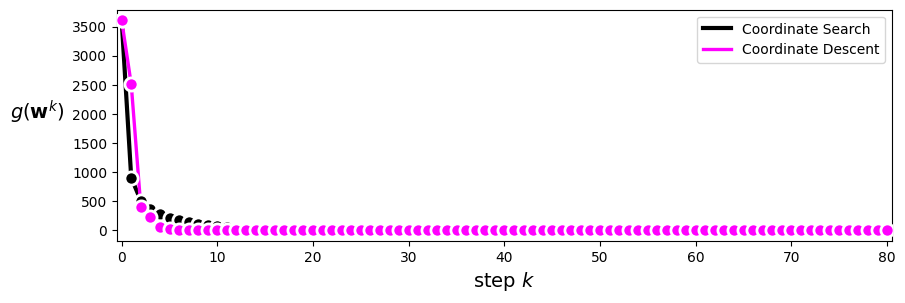

In [5]:
# defining g
def g(w):
    return 100 * (w[1] - w[0]**2)**2 + (w[0] - 1)**2

# parametric settings
alpha_choice = "diminishing"; w = np.array([-2,-2]); P = 40; num_samples = 1000

# running the algorithms
weight_history_cs, cost_history_cs = coordinate_search(g,alpha_choice,P,w)
weight_history_cd, cost_history_cd = coordinate_descent_zero_order(g,alpha_choice,P,w)

# plotting the cost histories
from MLRPlotting import static_plotter
# import custom plotting tools
static_plotter = static_plotter.Visualizer()
static_plotter.plot_cost_histories([cost_history_cs,cost_history_cd],start=0,points=True,labels=[r'Coordinate Search',r'Coordinate Descent'])	

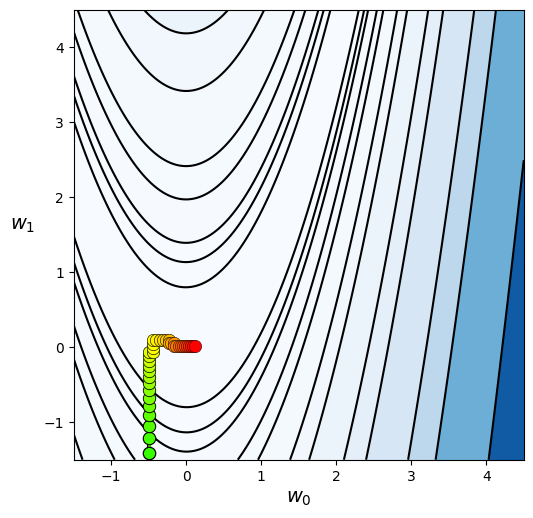

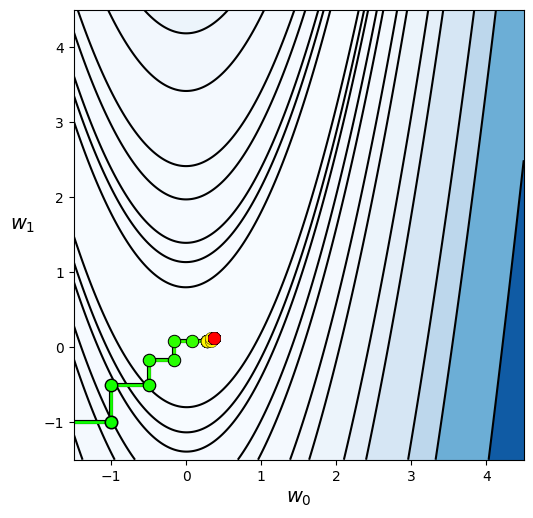

In [ ]:
# contour plots of the function g with overlayed w_history to visualize the paths taken by the algorithms
static_plotter.two_input_contour_plot(g,weight_history_cs,xmin = -1.5,xmax = 4.5,ymin = -1.5,ymax = 4.5,num_contours = 30,show_original = False)
# coordinate descent
static_plotter.two_input_contour_plot(g,weight_history_cd,xmin = -1.5,xmax = 4.5,ymin = -1.5,ymax = 4.5,num_contours = 30,show_original = False)

Cordinates descent seems to be more efficient, with bigger steps at the beginning it gets futher compared to  cordinate search.